# 14 — Image model: five outer folds

## tl;dr

This report evaluates the bounded B0 recipe and duration selection process on five patient
groups. Each outer fold supplies predictions from a model that did not use its
patients for fitting, recipe selection or epoch selection in this run.
The primary measure is **mean outer-fold average precision (AP)**. AP measures
how effectively melanoma images appear near the top of the model's ranking.
Higher is better; fold prevalence supplies a simple ranking baseline.

The notebook reads saved results only. It does not start training, fit
calibration, choose a cutoff or open the reserved test. A partial run displays
its progress and withholds final five-fold conclusions.


In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image

PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src/melanoma_detection").is_dir()
    and (path / "data/subset/processed/train_folds.csv").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.image_nested_reporting import load_saved_nested_run
from melanoma_detection.image_nested_calibration_reporting import load_saved_calibration_run

RUN_ID = "b0_nested_5fold_5h_v1"
CALIBRATION_RUN_ID = "b0_nested_calibration_5h_v1"
run = load_saved_nested_run(PROJECT_ROOT, RUN_ID)
if run["complete"]:
    result = run["evaluation"]
    lower, upper = result["primary_mean_fold_ap_ci95"]
    display(Markdown(f"**Mean outer-fold AP: {result['primary_mean_fold_average_precision']:.3f}** "
        f"(conditional 95% patient-bootstrap interval {lower:.3f}–{upper:.3f}). "
        f"{result['n_images']:,} images from {result['n_patients']:,} patients; "
        f"{result['n_positive']:,} melanoma images across all five folds."))
    print("Verified:", run["verification"])
else:
    display(Markdown(f"**Five-fold evaluation is incomplete: `{run['status']}`.** "
        "Rerun this notebook after training finishes. Final performance is withheld until "
        "all five folds have verified predictions and a final evaluation receipt."))
    progress = {key: value for key, value in run["summary"].items()
        if key in {"status", "completed_outer_folds", "stopping_reason", "updated_utc", "error"}}
    if progress:
        display(pd.DataFrame([progress]).astype(str).T.rename(columns={0: "Saved progress"}))


**Mean outer-fold AP: 0.145** (conditional 95% patient-bootstrap interval 0.103–0.222). 6,864 images from 422 patients; 128 melanoma images across all five folds.

Verified: canonical hash, prediction hash, evaluation hashes, exact five-fold coverage and recomputed fold metrics


## Context & Methods

The outer folds are the five existing patient groups in the canonical d1
development CSV. The complete process repeats independently inside every outer
training pool:

1. Build three inner patient folds. On the first inner fold, screen all **four
   B0 recipes for six epochs**: learning rate 3e-5 or 1e-4, crossed with unweighted
   or square-root-weighted loss. Only fitting patients determine the loss weight.
2. Choose the recipe with the highest screening AP. Scores within 0.0001 of the
   maximum tie; prefer unweighted loss and then the lower learning rate.
3. Confirm that selected recipe for **twelve total epochs on all three inner
   folds**. The compatible six-epoch first-fold checkpoint continues to twelve;
   the other two confirmation fits begin afresh.
4. Select the highest-AP epoch separately in each confirmation fit; exact ties
   keep the earlier epoch. The **median of those three best epochs** fixes the
   duration of a fresh refit on all outer training patients.
5. Predict the outer fold only after the fixed-duration refit completes. Outer
   labels do not guide fitting, recipe selection, epoch choice or stopping.

Confirmation AP chooses epochs inside training data; it is not outer performance.
The recipe and refit duration can differ between outer folds. Each canonical
image must receive exactly one outer prediction; missing, duplicate, extra or
relabelled rows fail verification.

### Key Assumptions

Images from one patient remain together in every partition. AP and other
metrics concern individual images; the uncertainty calculation resamples
**patients**, keeping all their images together. Patients are sampled with
replacement separately within each fixed outer fold. Draws lacking either
outcome in any fold are discarded consistently across all reported measures.
The report records requested, retained and rejected draws.

These intervals condition on the saved models, recipe choices and folds. They
do not represent variability from retraining or repeating model selection.
Mean fold AP is primary because scores from separate fitted models can have
different scales; pooled AP is a secondary description.

Earlier architecture, augmentation and recipe pilots used this development
dataset, and archived exploratory predictions used outer fold 0. This is
stronger **development evaluation**, but prior adaptation limits how fully it
represents an untouched evaluation. Freeze remaining decisions before the
single reserved-test evaluation.


In [2]:
manifest = run["manifest"]
protocol = manifest.get("protocol")
if protocol:
    display(Markdown(f"Recorded protocol: `{protocol}`"))
config = manifest.get("config", {})
if config:
    display(pd.DataFrame([config.get("training", {})]).astype(str).T.rename(columns={0: "Recorded training setting"}))
    selection = config.get("selection", {})
    settings = {name: value for name, value in selection.items() if name != "recipes"}
    display(pd.DataFrame([settings]).astype(str).T.rename(columns={0: "Recorded selection setting"}))
    display(pd.DataFrame(selection.get("recipes", [])))
print("Run directory:", run["run_dir"])
print("Canonical development input:", manifest.get("development_csv", "Run not started"))
print("Reserved test loaded by this report: False")


Recorded protocol: `bounded_b0_screen_confirm_v1`

,Recorded training setting
microbatch,64
effective_batch,64
min_microbatch,4
head_lr,0.001
weight_decay,0.0001
warmup_epochs,1
schedule_epochs,30
min_lr_factor,0.1
gradient_clip,1.0
amp,True


,Recorded selection setting
protocol,bounded_b0_screen_confirm_v1
outer_folds,"[0, 1, 2, 3, 4]"
inner_folds,3
screening_inner_fold,0
screening_epochs,6
confirmation_epochs,12
ap_tie_tolerance,0.0001
duration_rule,median_inner_best_epoch


,id,backbone_lr,loss_weight
0,lr3e5_none,0.00003,none
1,lr1e4_none,0.00010,none
2,lr3e5_sqrt,0.00003,sqrt_ratio
3,lr1e4_sqrt,0.00010,sqrt_ratio


Run directory: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\results\image_d1_runs\b0_nested_5fold_5h_v1
Canonical development input: data/subset/processed/train_folds.csv
Reserved test loaded by this report: False


### Recorded recipe and refit duration by outer fold

Each completed outer fold records the recipe chosen on its first inner split
and the fixed refit duration obtained from three confirmation fits. This table
documents what was selected, rather than ranking recipes using outer labels.
An unfinished fold keeps missing settings until its selection is saved.


In [3]:
fold_records = run["summary"].get("folds", [])
if fold_records:
    rows = [{"outer_fold": record["fold"], "status": record["status"],
        "selected_recipe": record.get("selected_recipe"),
        "refit_epochs": record.get("refit_epochs"),
        "incomplete_stage": record.get("stage")} for record in fold_records]
    display(pd.DataFrame(rows).sort_values("outer_fold").style.format(na_rep="Pending"))
else:
    print("No completed outer selection has been recorded yet.")

if run["complete"]:
    confirmation_rows = []
    for outer_fold in range(5):
        selection_path = run["run_dir"] / f"folds/{outer_fold}/selection.json"
        selection = json.loads(selection_path.read_text(encoding="utf-8"))
        for confirmation in selection["confirmation"]:
            confirmation_rows.append({"outer_fold": outer_fold,
                "recipe": selection["recipe"]["id"],
                "inner_fold": confirmation["inner_fold"],
                "best_epoch": confirmation["best_epoch"],
                "inner_selection_ap": confirmation["best_metrics"]["average_precision"],
                "outer_refit_epochs": selection["refit_epochs"]})
    display(pd.DataFrame(confirmation_rows).style.format({"inner_selection_ap": "{:.4f}"}))
    print("Inner confirmation AP selects epochs. Held-out outer AP appears in Results below.")


,outer_fold,status,selected_recipe,refit_epochs,incomplete_stage
0,0,complete,lr3e5_sqrt,6,Pending
1,1,complete,lr1e4_none,8,Pending
2,2,complete,lr1e4_sqrt,11,Pending
3,3,complete,lr1e4_sqrt,12,Pending
4,4,complete,lr1e4_sqrt,7,Pending


,outer_fold,recipe,inner_fold,best_epoch,inner_selection_ap,outer_refit_epochs
0,0,lr3e5_sqrt,0,6,0.1383,6
1,0,lr3e5_sqrt,1,9,0.1401,6
2,0,lr3e5_sqrt,2,3,0.0685,6
3,1,lr1e4_none,0,6,0.2310,8
4,1,lr1e4_none,1,12,0.2027,8
5,1,lr1e4_none,2,8,0.1007,8
6,2,lr1e4_sqrt,0,5,0.1785,11
7,2,lr1e4_sqrt,1,11,0.1097,11
8,2,lr1e4_sqrt,2,11,0.1539,11
9,3,lr1e4_sqrt,0,6,0.1418,12


Inner confirmation AP selects epochs. Held-out outer AP appears in Results below.


## Data

The verified population is the complete canonical development cohort. Counts
by fold make rare melanoma support and unequal image counts visible. All
models are scored on the same images when a metadata comparison is available.
No inner join can silently reduce the evaluation population.


In [4]:
if run["complete"]:
    columns = ["fold", "n_images", "n_patients", "n_positive", "prevalence"]
    display(run["fold_metrics"][columns].style.format({"prevalence": "{:.2%}"}))
else:
    print("Complete population counts will appear after five-fold verification.")


,fold,n_images,n_patients,n_positive,prevalence
0,0,1370,84,25,1.82%
1,1,1372,84,26,1.90%
2,2,1381,87,26,1.88%
3,3,1371,82,25,1.82%
4,4,1370,85,26,1.90%


## Results

### Ranking and fold variation

The fold table and AP plot show how ranking performance varies between patient
groups. The spread between five fold scores is descriptive variability, not a
confidence interval. Precision–recall is particularly informative here because
melanoma images are uncommon; ROC shows a complementary ranking view.


,fold,n_images,n_patients,n_positive,prevalence,average_precision,roc_auc,log_loss,brier
0,0,1370,84,25,0.0182,0.1501,0.8671,0.0791,0.0193
1,1,1372,84,26,0.0190,0.1684,0.8402,0.0942,0.0215
2,2,1381,87,26,0.0188,0.1052,0.8443,0.0926,0.0233
3,3,1371,82,25,0.0182,0.0871,0.8146,0.0981,0.0215
4,4,1370,85,26,0.0190,0.2128,0.8378,0.0831,0.0188


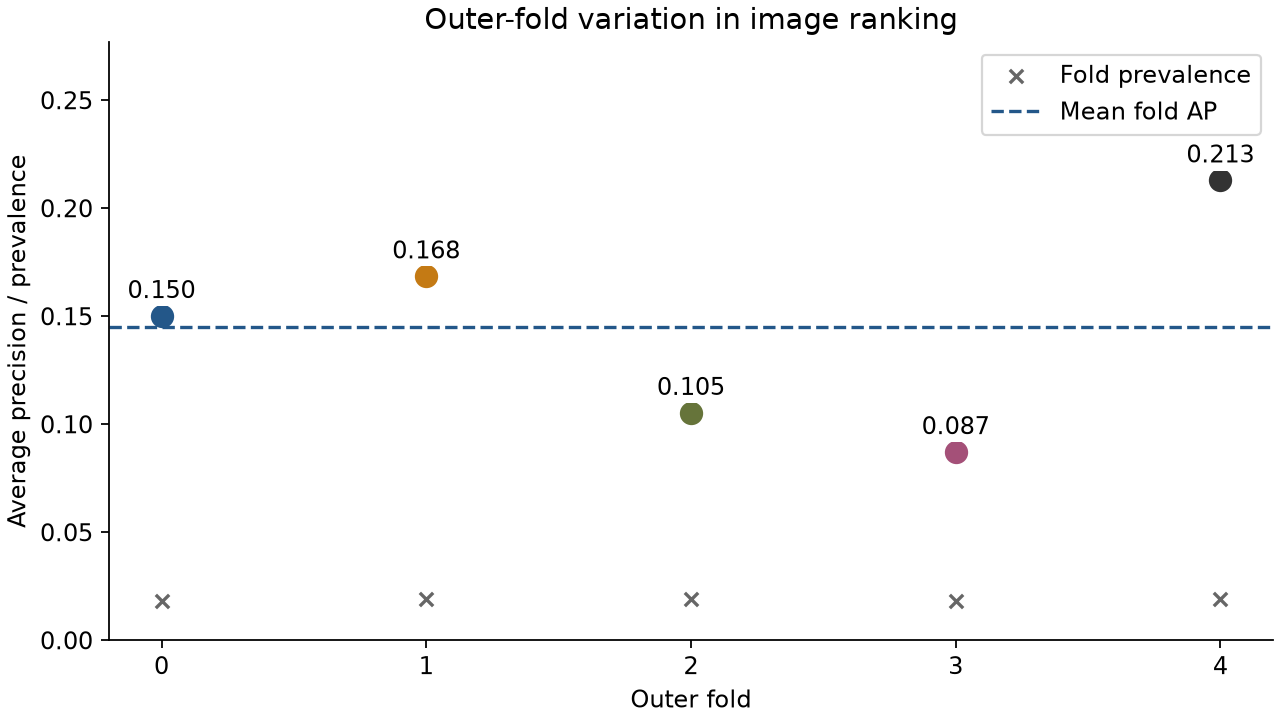

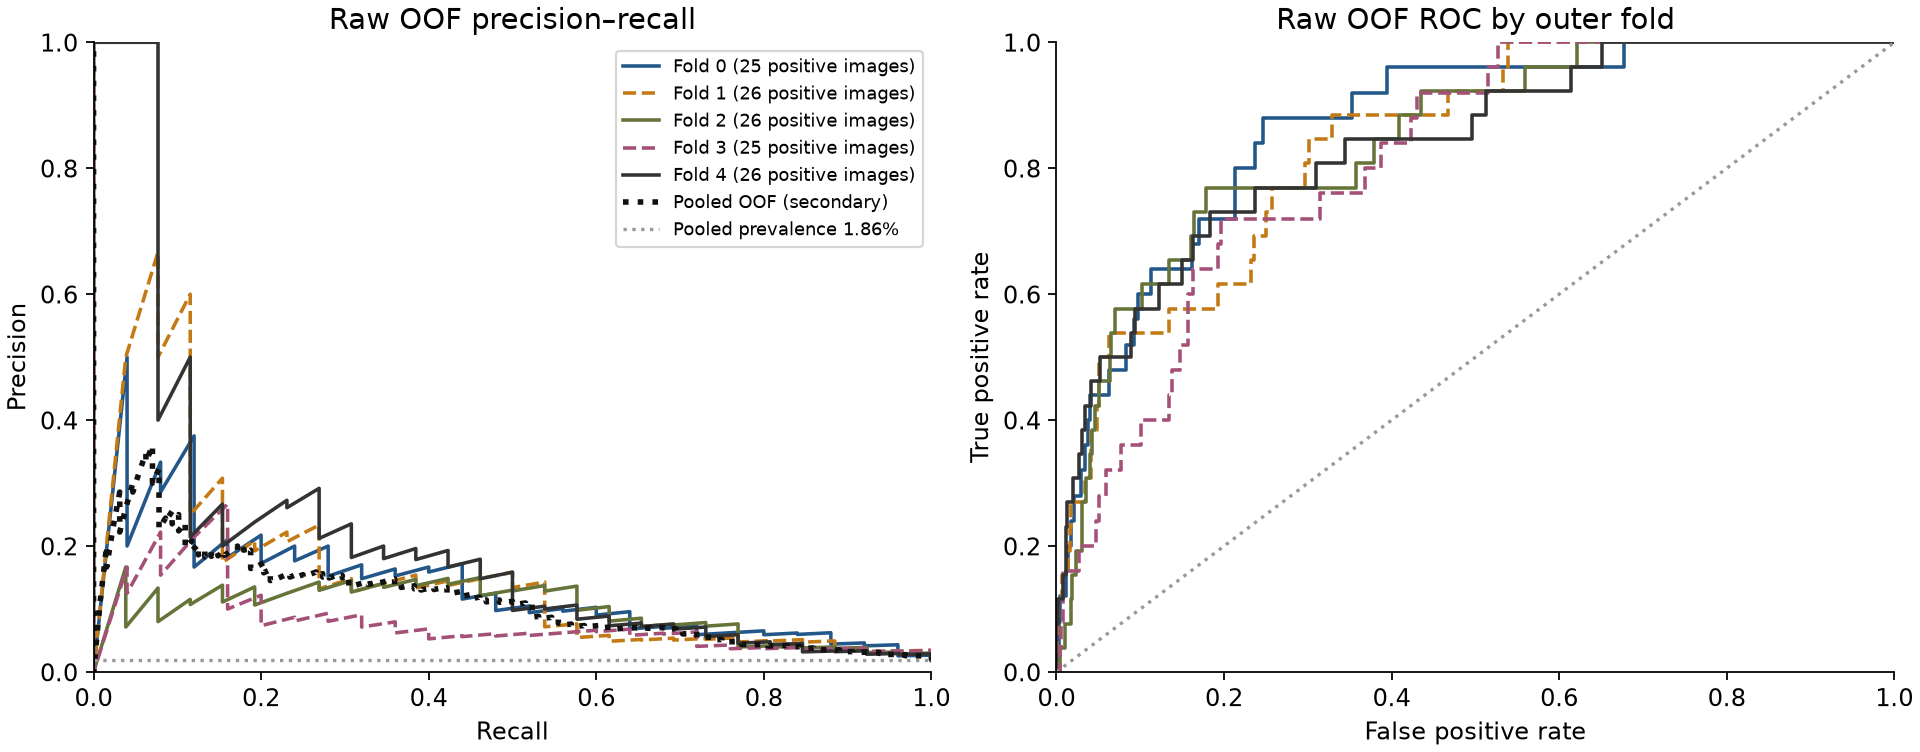

,model,aggregation,metric,estimate,ci_lower,ci_upper,bootstrap_replicates,valid_replicates,rejected_single_class_replicates,seed
0,image,mean_fold,average_precision,0.1447,0.1033,0.2225,2000,2000,0,42
1,image,mean_fold,roc_auc,0.8408,0.7953,0.8747,2000,2000,0,42
2,image,mean_fold,log_loss,0.0894,0.0735,0.1079,2000,2000,0,42
3,image,mean_fold,brier,0.0209,0.0168,0.0255,2000,2000,0,42
4,image,pooled,average_precision,0.1160,0.0759,0.1785,2000,2000,0,42
5,image,pooled,roc_auc,0.8279,0.7824,0.8675,2000,2000,0,42
6,image,pooled,log_loss,0.0894,0.0731,0.1073,2000,2000,0,42
7,image,pooled,brier,0.0209,0.0167,0.0253,2000,2000,0,42


95% percentile patient-cluster bootstrap, resampling patients within each outer fold. All images of a sampled patient stay together. Single-class draws in any fold are excluded from all metrics and comparisons. Intervals are conditional on these fitted models, selected recipes, fixed folds and observed fold memberships; no retraining or recipe reselection is performed. They omit training variability and prior pilot adaptivity.


In [5]:
if run["complete"]:
    display(run["fold_metrics"].style.format({name: "{:.4f}" for name in
        ["prevalence", "average_precision", "roc_auc", "log_loss", "brier"]}))
    display(Image(filename=str(run["run_dir"] / "figures/outer_fold_average_precision.png")))
    display(Image(filename=str(run["run_dir"] / "figures/outer_fold_pr_roc.png")))
    intervals = run["intervals"]
    display(intervals[(intervals.model == "image")].drop(columns=["interval"]).style.format(
        {"estimate": "{:.4f}", "ci_lower": "{:.4f}", "ci_upper": "{:.4f}"}))
    print(run["evaluation"]["bootstrap_method"])


### Raw probabilities and the declared 0.5 cutoff

Log loss and Brier score examine probability quality; lower is better. The
reliability plot compares mean raw score with the observed melanoma fraction
in fixed bins, and shows how many images support each point. It is descriptive:
sparse bins can be unstable. Class weighting can alter raw probability scale.

The confusion counts use the declared rule **raw score ≥ 0.5**. This cutoff is
a transparent default illustration, not a tuned operating point or a clinical
recommendation. No new threshold or calibration model is fitted here.


,Raw cutoff 0.5
threshold,0.5
score_type,raw_base_probability
decision_rule,score >= threshold
TP,15
FP,59
TN,6677
FN,113
sensitivity,0.117188
specificity,0.991241
precision,0.202703


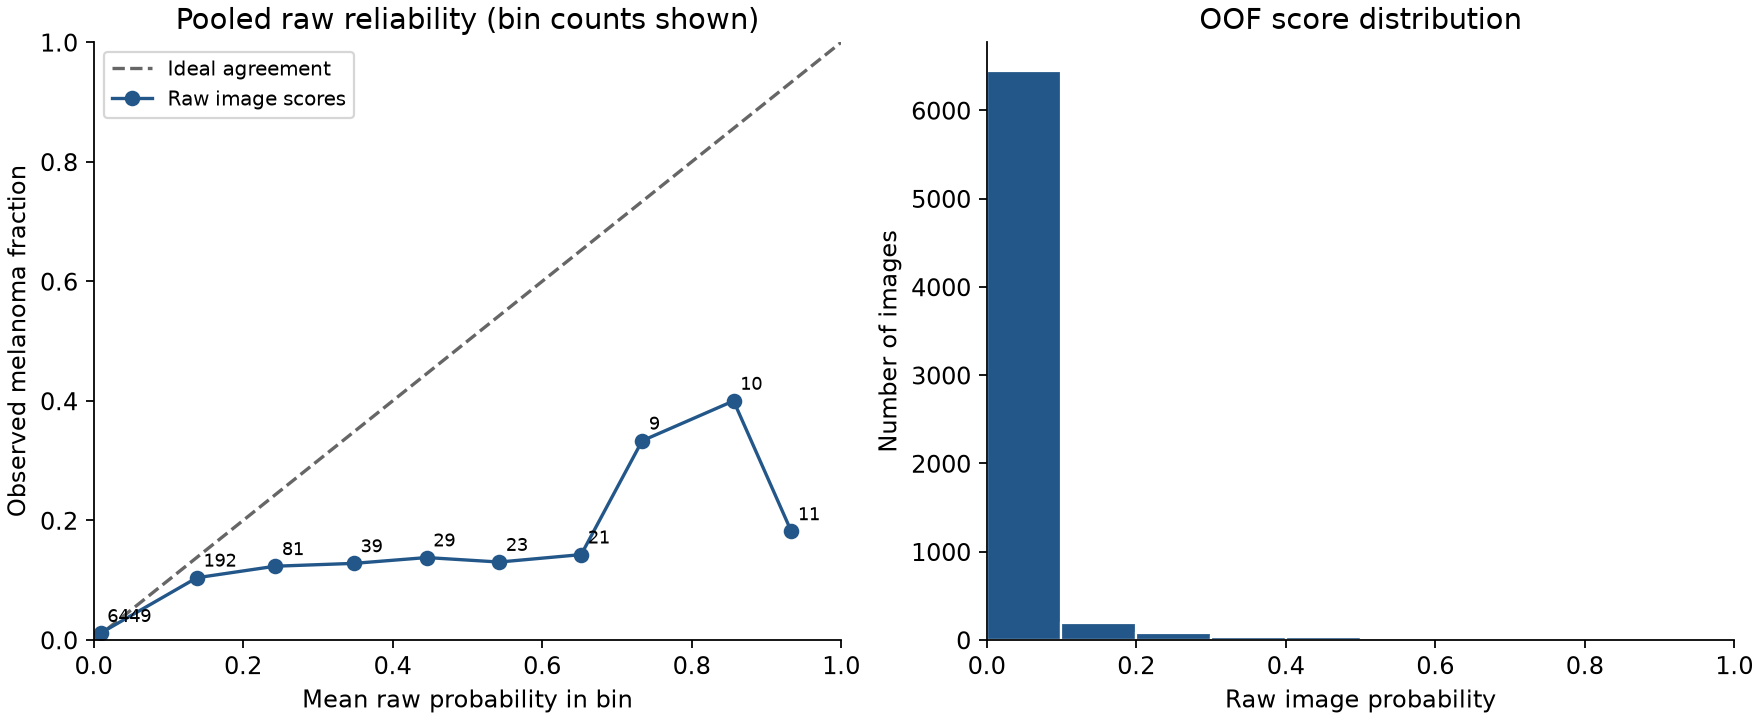

,bin,lower,upper,n_images,n_positive,mean_probability,observed_prevalence
0,0,0.0,0.1,6449,74,0.0094,0.0115
1,1,0.1,0.2,192,20,0.1382,0.1042
2,2,0.2,0.3,81,10,0.2430,0.1235
3,3,0.3,0.4,39,5,0.3482,0.1282
4,4,0.4,0.5,29,4,0.4455,0.1379
5,5,0.5,0.6,23,3,0.5426,0.1304
6,6,0.6,0.7,21,3,0.6522,0.1429
7,7,0.7,0.8,9,3,0.7338,0.3333
8,8,0.8,0.9,10,4,0.8561,0.4000
9,9,0.9,1.0,11,2,0.9332,0.1818


In [6]:
if run["complete"]:
    display(run["threshold_metrics"].T.rename(columns={0: "Raw cutoff 0.5"}))
    display(Image(filename=str(run["run_dir"] / "figures/raw_reliability.png")))
    display(run["reliability"].style.format({"lower": "{:.1f}", "upper": "{:.1f}",
        "mean_probability": "{:.4f}", "observed_prevalence": "{:.4f}"}, na_rep="Empty bin"))


### Optional training-only calibration and the 80%-recall scenario

This separate stage has its own run directory. It may start after the raw
five-fold evaluation finishes, if three fresh fixed-duration inner refits per
outer fold fit the same session deadline. Each uses that outer pool's already
selected recipe and median epoch duration. Its training-only OOF predictions
fit a logistic calibration map on logits (`C=1`) and choose the highest cutoff
reaching 80% malignant recall on those training predictions. A failed or
non-positive-slope map is recorded and leaves the separate calibration stage
incomplete; the raw report remains available. Complete frozen maps and cutoffs
are then applied to the unchanged raw outer predictions.

All five calibration folds must finish before the comparisons below appear.
Calibration is assessed through held-out log loss, Brier and reliability.
Positive-slope maps preserve ordering within a fold, so fold AP/ROC-AUC should
stay the same; numerical clipping or ties require inspection if they change.
Pooled AP may change when the five folds' score scales change.

The 80% recall value is a **training selection target**, not a promise about
actual outer recall or a clinically validated target. Report the actual held-out
recall, precision, F1, specificity and confusion counts. Calibration maps and
cutoffs remain fixed in the reported conditional bootstrap intervals. The raw
five-fold status and matched metadata comparison remain unchanged.


**The separate five-fold calibration report is complete and verified.**

Verified: both canonical/prediction receipts, complete fold receipts, final artifact hashes and recomputed outer metrics/counts


,average_precision,roc_auc,log_loss,brier
calibrated,0.1447,0.8408,0.0791,0.0174
raw,0.1447,0.8408,0.0894,0.0209


,model,aggregation,metric,estimate,ci_lower,ci_upper,bootstrap_replicates,valid_replicates,rejected_single_class_replicates,seed
2,calibrated,mean_fold,log_loss,0.0791,0.0649,0.0957,2000,2000,0,42
3,calibrated,mean_fold,brier,0.0174,0.0136,0.0218,2000,2000,0,42
6,calibrated,pooled,log_loss,0.0791,0.0646,0.0949,2000,2000,0,42
7,calibrated,pooled,brier,0.0174,0.0135,0.0217,2000,2000,0,42
10,raw,mean_fold,log_loss,0.0894,0.0735,0.1079,2000,2000,0,42
11,raw,mean_fold,brier,0.0209,0.0168,0.0255,2000,2000,0,42
14,raw,pooled,log_loss,0.0894,0.0731,0.1073,2000,2000,0,42
15,raw,pooled,brier,0.0209,0.0167,0.0253,2000,2000,0,42


,comparison,aggregation,metric,difference,ci_lower,ci_upper,bootstrap_replicates,valid_replicates,rejected_single_class_replicates,seed
2,calibrated minus raw,mean_fold,log_loss,-0.0103,-0.0163,-0.0050,2000,2000,0,42
3,calibrated minus raw,mean_fold,brier,-0.0035,-0.0052,-0.0020,2000,2000,0,42
6,calibrated minus raw,pooled,log_loss,-0.0103,-0.0158,-0.0049,2000,2000,0,42
7,calibrated minus raw,pooled,brier,-0.0035,-0.0051,-0.0020,2000,2000,0,42


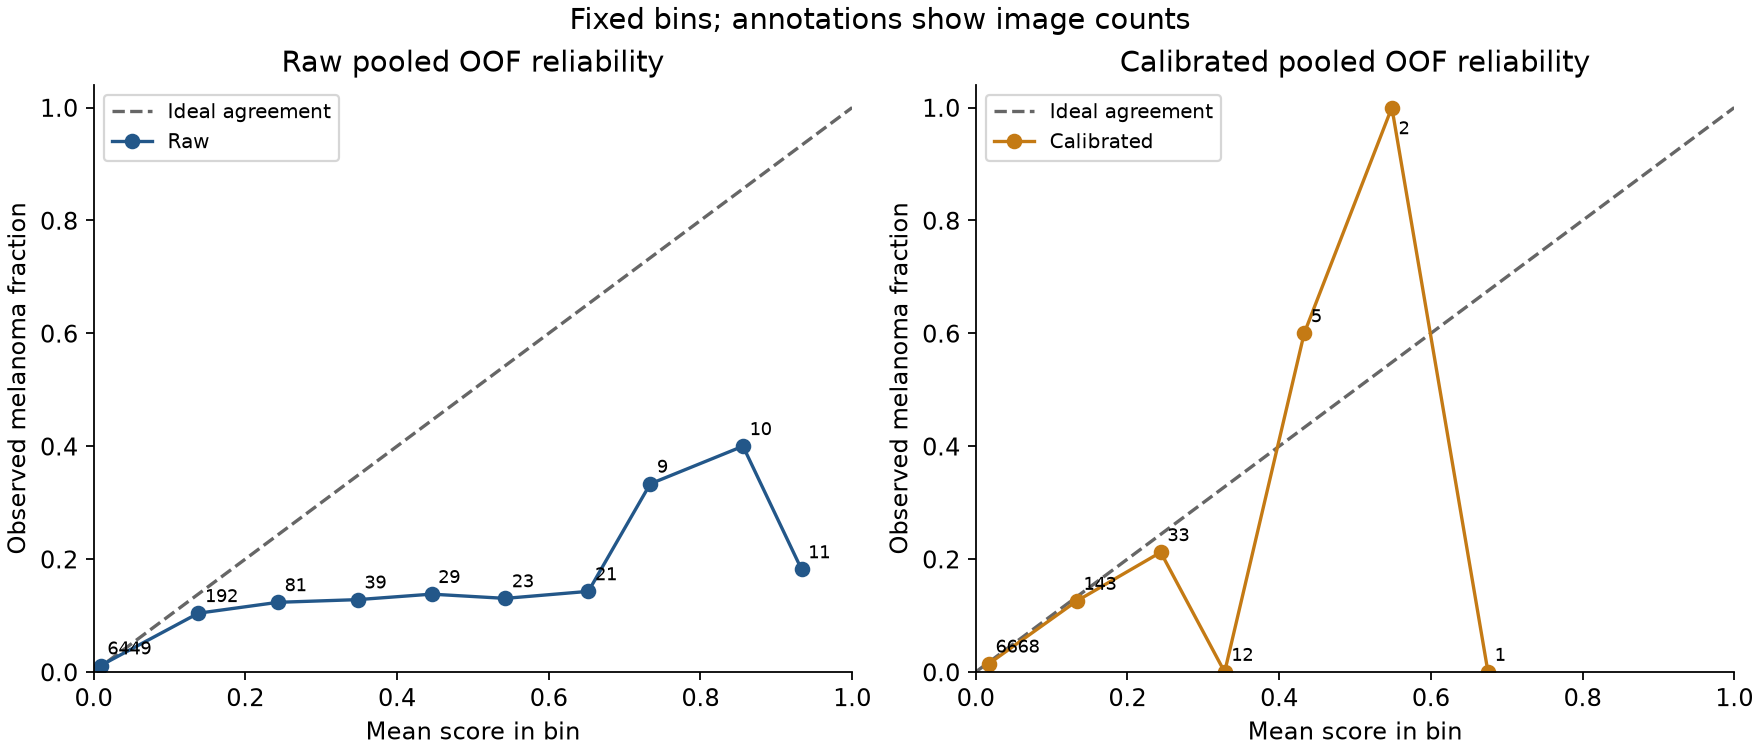

Negative calibrated-minus-raw log-loss/Brier differences favour calibration.
95% percentile patient-cluster bootstrap, resampling patients within each outer fold. All images of a sampled patient stay together. Single-class draws in any fold are excluded from all metrics and comparisons. Intervals are conditional on these fitted models, selected recipes, fixed folds and observed fold memberships; no retraining or recipe reselection is performed. They omit training variability and prior pilot adaptivity. Calibration maps and thresholds are also held fixed.


In [7]:
calibration = load_saved_calibration_run(PROJECT_ROOT, CALIBRATION_RUN_ID)
if calibration["complete"]:
    display(Markdown("**The separate five-fold calibration report is complete and verified.**"))
    print("Verified:", calibration["verification"])
    display(pd.DataFrame(calibration["evaluation"]["mean_fold_metrics"]).T.style.format("{:.4f}"))
    probability_intervals = calibration["intervals"]
    display(probability_intervals[probability_intervals.metric.isin(["log_loss", "brier"])]
        .drop(columns="interval").style.format({"estimate": "{:.4f}", "ci_lower": "{:.4f}", "ci_upper": "{:.4f}"}))
    differences = calibration["paired_differences"]
    display(differences[differences.metric.isin(["log_loss", "brier"])].style.format(
        {"difference": "{:+.4f}", "ci_lower": "{:+.4f}", "ci_upper": "{:+.4f}"}))
    display(Image(filename=str(calibration["run_dir"] / "figures/raw_vs_calibrated_reliability.png")))
    print("Negative calibrated-minus-raw log-loss/Brier differences favour calibration.")
    print(calibration["evaluation"]["bootstrap_method"])
else:
    display(Markdown(f"**Separate calibration stage: `{calibration['status']}`.** "
        "No aggregate calibration or training-selected-threshold result is claimed until "
        "all five calibration folds and reporting checks complete."))
    progress = {key: value for key, value in calibration["summary"].items()
        if key in {"completed_outer_folds", "stopping_reason", "updated_utc", "error"}}
    if progress:
        display(pd.DataFrame([progress]).astype(str).T.rename(columns={0: "Calibration progress"}))


,fold,raw_average_precision,calibrated_average_precision,ap_difference,raw_roc_auc,calibrated_roc_auc,ap_invariant,roc_auc_invariant,changed_training_selected_decisions
0,0,0.1501,0.1501,+0.000000,0.8671,0.8671,True,True,0
1,1,0.1684,0.1684,+0.000000,0.8402,0.8402,True,True,0
2,2,0.1052,0.1052,+0.000000,0.8443,0.8443,True,True,0
3,3,0.0871,0.0871,+0.000000,0.8146,0.8146,True,True,0
4,4,0.2128,0.2128,+0.000000,0.8378,0.8378,True,True,0


,fold,model,threshold,n_images,n_positive,TP,FN,FP,TN,recall,precision,f1,specificity,flagged_fraction
0,0,raw,0.0160,1370,25,22,3,441,904,0.8800,0.0475,0.0902,0.6721,0.3380
1,0,calibrated,0.0156,1370,25,22,3,441,904,0.8800,0.0475,0.0902,0.6721,0.3380
2,1,raw,0.0094,1372,26,16,10,292,1054,0.6154,0.0519,0.0958,0.7831,0.2245
3,1,calibrated,0.0170,1372,26,16,10,292,1054,0.6154,0.0519,0.0958,0.7831,0.2245
4,2,raw,0.0007,1381,26,26,0,904,451,1.0000,0.0280,0.0544,0.3328,0.6734
5,2,calibrated,0.0166,1381,26,26,0,904,451,1.0000,0.0280,0.0544,0.3328,0.6734
6,3,raw,0.0004,1371,25,24,1,708,638,0.9600,0.0328,0.0634,0.4740,0.5339
7,3,calibrated,0.0136,1371,25,24,1,708,638,0.9600,0.0328,0.0634,0.4740,0.5339
8,4,raw,0.0153,1370,26,18,8,233,1111,0.6923,0.0717,0.1300,0.8266,0.1832
9,4,calibrated,0.0152,1370,26,18,8,233,1111,0.6923,0.0717,0.1300,0.8266,0.1832


,fold,model,n_images,n_positive,TP,FN,FP,TN,recall,precision,f1,specificity,flagged_fraction
0,pooled,raw,6864,128,106,22,2578,4158,0.8281,0.0395,0.0754,0.6173,0.3910
1,pooled,calibrated,6864,128,106,22,2578,4158,0.8281,0.0395,0.0754,0.6173,0.3910


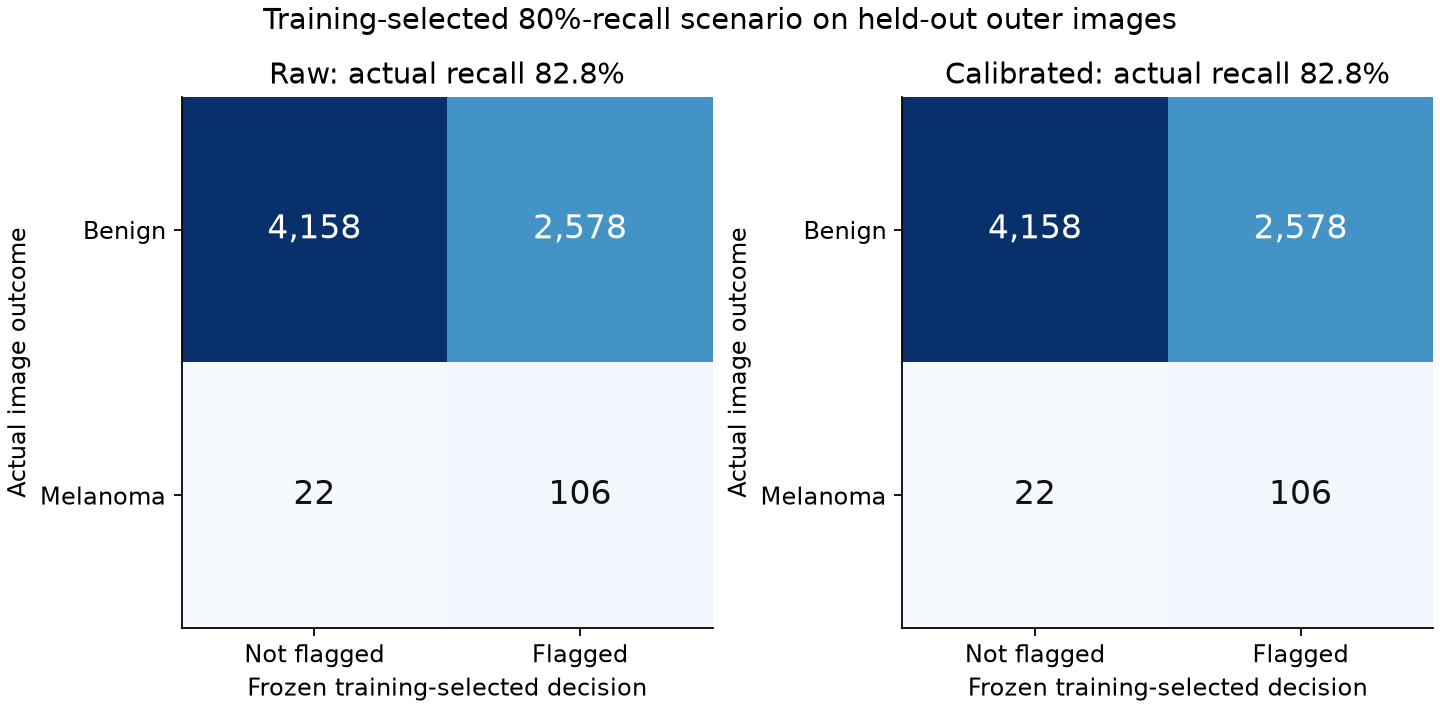

The 80% target is used only on training-only OOF scores. Actual held-out recall can be lower or higher. This is an academic scenario, without clinical validation.

In [8]:
if calibration["complete"]:
    display(calibration["ranking_invariance"].style.format({"raw_average_precision": "{:.4f}",
        "calibrated_average_precision": "{:.4f}", "ap_difference": "{:+.6f}",
        "raw_roc_auc": "{:.4f}", "calibrated_roc_auc": "{:.4f}"}))
    if calibration["evaluation"]["ranking_warning"]:
        display(Markdown(calibration["evaluation"]["ranking_warning"]))
    if calibration["evaluation"]["decision_warning"]:
        display(Markdown(calibration["evaluation"]["decision_warning"]))
    scenario_columns = ["fold", "model", "threshold", "n_images", "n_positive", "TP", "FN", "FP", "TN",
        "recall", "precision", "f1", "specificity", "flagged_fraction"]
    formats = {name: "{:.4f}" for name in ["threshold", "recall", "precision", "f1", "specificity", "flagged_fraction"]}
    display(calibration["scenario_by_fold"][scenario_columns].style.format(formats, na_rep="Undefined"))
    display(calibration["scenario_pooled"][scenario_columns].drop(columns="threshold")
        .style.format(formats, na_rep="Undefined"))
    display(Image(filename=str(calibration["run_dir"] / "figures/training_selected_threshold_counts.png")))
    display(Markdown(calibration["evaluation"]["threshold_interpretation"]))


### Matched metadata comparison

When present, metadata scores come from the existing hash-recorded OOF
prediction bundle with verified canonical identities. The image-minus-metadata
interval uses the **same patient draw** for both models. Positive AP or ROC-AUC
differences favour the image model; negative log-loss or Brier differences
favour it. These are paired development comparisons after prior diagnostics.


The saved image-versus-metadata comparisons in this section use the historical fixed NN ensemble and fixed spline. They were not fitted or recalculated for the new tuned NN. The additional assessment below identifies the new versioned fixed/tuned NN experiment separately; historical image calibration and decision cutoffs remain attached to their original procedures.

In [9]:
if run["complete"] and not run["metadata_comparison"].empty:
    display(run["metadata_comparison"].style.format({"difference": "{:+.4f}",
        "ci_lower": "{:+.4f}", "ci_upper": "{:+.4f}"}))
elif run["complete"]:
    print("No verified matched metadata comparison was saved for this run.")


,comparison,aggregation,metric,difference,ci_lower,ci_upper,bootstrap_replicates,valid_replicates,rejected_single_class_replicates,seed
0,image minus metadata_mlp_mean,mean_fold,average_precision,+0.0865,+0.0317,+0.1550,2000,2000,0,42
1,image minus metadata_mlp_mean,mean_fold,roc_auc,+0.1620,+0.1026,+0.2143,2000,2000,0,42
2,image minus metadata_mlp_mean,mean_fold,log_loss,+0.0004,-0.0096,+0.0098,2000,2000,0,42
3,image minus metadata_mlp_mean,mean_fold,brier,+0.0028,+0.0007,+0.0049,2000,2000,0,42
4,image minus metadata_mlp_mean,pooled,average_precision,+0.0695,+0.0305,+0.1256,2000,2000,0,42
5,image minus metadata_mlp_mean,pooled,roc_auc,+0.1556,+0.0953,+0.2139,2000,2000,0,42
6,image minus metadata_mlp_mean,pooled,log_loss,+0.0004,-0.0095,+0.0094,2000,2000,0,42
7,image minus metadata_mlp_mean,pooled,brier,+0.0028,+0.0007,+0.0048,2000,2000,0,42
8,image minus metadata_spline_raw,mean_fold,average_precision,+0.0799,+0.0179,+0.1510,2000,2000,0,42
9,image minus metadata_spline_raw,mean_fold,roc_auc,+0.1779,+0.1141,+0.2290,2000,2000,0,42


## Takeaways

Use mean-fold AP and its conditional patient interval together with fold
variation when assessing this image model. Pooled AP, raw-score reliability and
the declared-cutoff confusion counts answer complementary questions. Preserve
the development caveat when presenting these results; the reserved test is the
remaining independent assessment after all decisions are frozen.


In [10]:
if run["complete"]:
    result = run["evaluation"]
    display(Markdown(f"The five fold AP scores range from "
        f"**{run['fold_metrics'].average_precision.min():.3f} to "
        f"{run['fold_metrics'].average_precision.max():.3f}**. "
        f"Pooled AP is **{result['pooled_metrics_secondary']['average_precision']:.3f}** "
        f"on a cohort with **{result['prevalence']:.2%}** melanoma images."))
    display(Markdown(result["development_caveat"]))
else:
    print("Performance takeaways remain pending until every outer fold completes.")


The five fold AP scores range from **0.087 to 0.213**. Pooled AP is **0.116** on a cohort with **1.86%** melanoma images.

Development OOF evidence after earlier architecture, augmentation and recipe pilots; fold 0 also has archived exploratory results. Independent outer prediction within this run does not erase earlier adaptation to this development dataset. The locked test remains necessary after decisions are frozen.

## Additional experiment: tuned metadata neural network

Stage 07 now searches 36 predefined combinations of network width, learning rate and dropout. The three-seed mean is selected using inner patient groups, then evaluated on the excluded outer patients. This extension was specified after earlier development results had been examined, so it remains development evidence. It does not automatically replace the spline.

Read unweighted mean outer-fold AP first. Pooled AP and ROC-AUC remain secondary. Paired intervals resample whole patients within each outer fold while holding the fitted models fixed. They describe uncertainty conditional on these saved predictions and do not include the full variability of retraining or adaptively choosing another search. Log loss, Brier score and reliability assess raw probability quality; completed fixed-spline calibration and training-selected cutoffs do not transfer to the tuned NN.

,model,average_precision,roc_auc,log_loss,brier
5,spline,0.06486,0.66289,0.08974,0.01814
12,spline_tuned,0.06887,0.66628,0.08961,0.01810
47,nn_mean,0.05812,0.67878,0.08896,0.01810
54,nn_tuned,0.06568,0.68131,0.08867,0.01807


,comparison,metric,difference,ci_lower,ci_upper
0,nn_tuned minus fixed_nn,average_precision,0.00756,-0.00268,0.02393
1,nn_tuned minus fixed_nn,roc_auc,0.00253,-0.00606,0.01038
2,nn_tuned minus fixed_nn,log_loss,-0.00029,-0.00076,0.00023
3,nn_tuned minus fixed_nn,brier,-0.00003,-0.00006,0.00000
8,nn_tuned minus fixed_spline,average_precision,0.00083,-0.01342,0.00814
9,nn_tuned minus fixed_spline,roc_auc,0.01843,-0.00765,0.03830
10,nn_tuned minus fixed_spline,log_loss,-0.00107,-0.00241,0.00031
11,nn_tuned minus fixed_spline,brier,-0.00007,-0.00020,0.00008
16,nn_tuned minus tuned_spline,average_precision,-0.00319,-0.02278,0.00397
17,nn_tuned minus tuned_spline,roc_auc,0.01503,-0.02214,0.04041


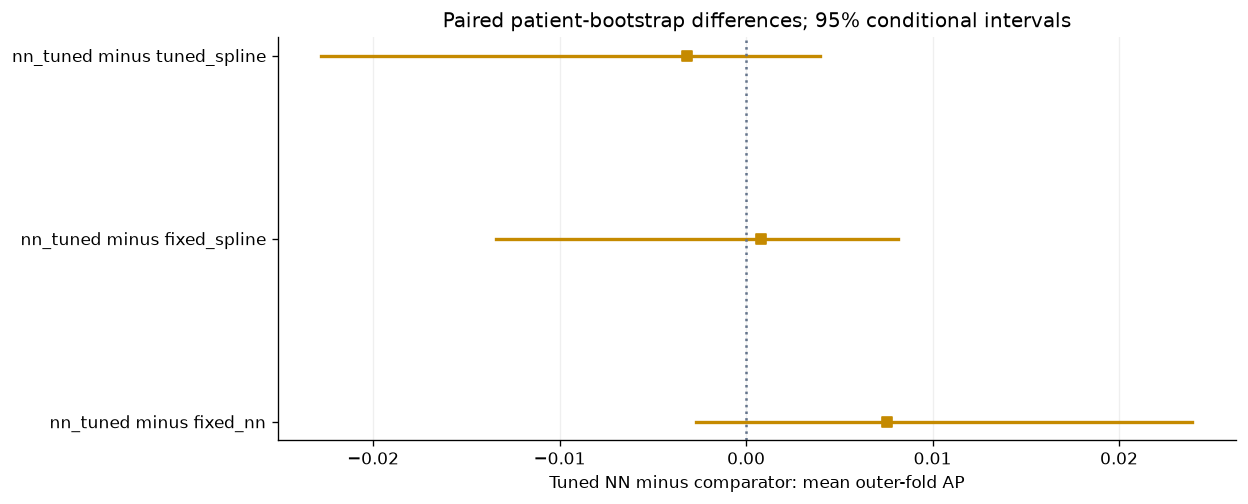

**Observed primary comparison:** fixed spline AP 0.0649; tuned NN AP 0.0657. The difference is +0.0008, with a 95% conditional patient interval [-0.0134, +0.0081]. These are development results. The selected final procedure, its calibration and its decision threshold remain separate decisions before reserved-test evaluation.

In [11]:
from pathlib import Path
import sys
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.metadata_nn_tuning_evaluation import show_assessment
import matplotlib.pyplot as plt
plt.rcdefaults()
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
show_assessment(PROJECT_ROOT, 'original')
